# Parametric vs ML Curve Fitting: Nelson–Siegel–Svensson vs Gaussian Process vs Neural Net

Every valuation, VaR number and hedge starts from a yield curve, and a curve has to do several things at once: fit the bonds, price bonds it has not seen, stay smooth, extrapolate sensibly and not jump when the market barely moves. Flexible models fit better but often generalise worse. This notebook puts the central banks' parametric model against two machine-learning alternatives on real Treasury bonds.

**What it does.** It fits the U.S. Treasury yield curve three ways: the parametric Nelson–Siegel–Svensson model that central banks publish, a Gaussian process and a neural network.

They are compared as a curve desk or model validator would: out-of-sample pricing error, smoothness, forward-curve behaviour, extrapolation, rich/cheap signals and day-to-day stability.

**Data.** The bond-level holdings of the iShares U.S. Treasury Bond ETF (GOVT), about 200 Treasury notes and bonds with yields and maturities, plus this year's daily Treasury par yield curves (U.S. Treasury).

**Methods.** NSS by multi-start non-linear least squares, GP regression with an RBF + noise kernel on log maturity, and an ensemble of small PyTorch MLPs with a curvature penalty, tested with 10-fold cross-validation and leave-one-tenor-out tests through time.

**Key output.** A scorecard (CV error in bp, roughness, wiggles, extrapolation), fitted curves with their implied forwards, the rich and cheap bonds each model flags, and the stability of each fit through 2026.

## 1. Why curve fitting matters to a risk function

Every valuation, VaR and hedge starts from a curve. The curve must:

1. **price the bonds it is fitted to** (small residuals),
2. **price bonds it was not fitted to** (generalise, measured by cross-validation),
3. be **smooth**, with forwards that do not oscillate, because hedge ratios and key-rate durations are derivatives of the curve,
4. **extrapolate sensibly** beyond the last bond, and
5. be **stable**: a small market move should not reshape the curve.

These goals conflict. A flexible model fits better and generalises worse. That is the bias–variance trade-off in its most concrete financial form.

| Model | Form | Strength | Risk |
|---|---|---|---|
| **NSS** (Svensson 1994; used by the Fed's GSW curve, ECB, BIS) | $y(\tau)=\beta_0+\beta_1\frac{1-e^{-\tau/\lambda_1}}{\tau/\lambda_1}+\beta_2\Big(\frac{1-e^{-\tau/\lambda_1}}{\tau/\lambda_1}-e^{-\tau/\lambda_1}\Big)+\beta_3\Big(\frac{1-e^{-\tau/\lambda_2}}{\tau/\lambda_2}-e^{-\tau/\lambda_2}\Big)$ | 6 interpretable parameters (level, slope, two humps), smooth by construction | may miss local structure; parameters unstable when $\lambda_1\approx\lambda_2$ |
| **Gaussian process** | prior over smooth functions of $\log\tau$, kernel $k=\sigma^2\exp(-\Delta^2/2\ell^2)+\sigma_n^2\delta$ | flexible, gives error bands, learns its own smoothness | reverts to the mean outside the data |
| **Neural network** | ensemble of MLPs $\log\tau\mapsto y$ with a penalty on $\int y''^2$ | flexible, any shape | needs regularisation; extrapolation is arbitrary |

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
from scipy.optimize import least_squares
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

ISHARES_FUNDS = {"GOVT": "239468"}
SLEEVE_BY_FUND = {"GOVT": "US Treasuries"}
SEED = 5
N_FOLDS = 10
NN_ENSEMBLE = 5
# evaluation grid in years (beyond 30y = extrapolation)
TAU_GRID = np.linspace(0.25, 32, 600)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(f"torch {torch.__version__} · run on {dt.date.today():%Y-%m-%d}")

torch 2.14.1+cu130 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "NSS": PALETTE[0],
    "Gaussian process": PALETTE[2],
    "Neural net": PALETTE[1],
}

## 3. Data: Treasury notes and bonds held by GOVT

The holdings file gives each bond's coupon, maturity and yield to maturity as of the fund's valuation date. Three groups are removed before fitting:

- bonds maturing within three months, whose yields are driven by money-market technicals rather than the term structure;
- floating-rate notes;
- **Treasury STRIPS**. A STRIPS yield is a zero-coupon yield, and mixing it with coupon-bond yields to maturity puts two different curves in one fit. A first version that kept them flagged every STRIPS as "cheap" by 10–20 bp, which is the coupon effect, not relative value.

In [3]:
def fetch_holdings(ticker: str) -> pd.DataFrame:
    """
    Download one iShares fund's holdings file and return the holdings table as
    text columns.
    """
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=30
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    table = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    table["fund"], table["as_of"] = ticker, as_of
    return table


raw_holdings = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)


def to_number(s):
    """'1,234.50' -> 1234.5 ; '-' or '' -> NaN."""
    return pd.to_numeric(
        s.astype(str).str.replace(",", "", regex=False).str.strip(),
        errors="coerce",
    )


col = lambda name, default="": (
    raw_holdings[name]
    if name in raw_holdings
    else pd.Series(default, index=raw_holdings.index)
)
bonds = pd.DataFrame({
    "fund": raw_holdings["fund"],
    "name": raw_holdings["Name"],
    "sector": col("Sector").fillna(""),
    "asset_class": col("Asset Class").fillna(""),
    "currency": col("Currency", "USD").fillna(""),
    "isin": col("ISIN"),
    "weight_pct": to_number(raw_holdings["Weight (%)"]),
    "clean_price": to_number(col("Price", np.nan)),
    "coupon_pct": to_number(raw_holdings["Coupon (%)"]),
    "ishares_duration": to_number(col("Duration", np.nan)),
    "ishares_ytm_pct": to_number(col("YTM (%)", np.nan)),
    "maturity": pd.to_datetime(
        raw_holdings["Maturity"], format="%b %d, %Y", errors="coerce"
    ).fillna(
        pd.to_datetime(
            raw_holdings["Maturity"], format="mixed", errors="coerce"
        )
    ),
    "as_of": raw_holdings["as_of"],
})
# Sleeve = the fund it came from; the corporate fund is split into banks and
# other corporates by sector
bonds["sleeve"] = [
    SLEEVE_BY_FUND.get(f)
    or ("Banks" if re.search("bank", s, re.I) else "Corporates")
    for f, s in zip(bonds["fund"], bonds["sector"])
]


def clean_price_from_ytm(coupon_pct, ytm_pct, maturity, settle):
    """
    Clean price per 100 from a semi-annual yield, used when a holdings file has
    no Price column.
    """
    if (
        any(pd.isna(v) for v in (coupon_pct, ytm_pct, maturity, settle))
        or maturity <= settle
    ):
        return np.nan
    c, y = coupon_pct / 2, ytm_pct / 200
    # coupon dates, walking back from maturity
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfs = dates[-1], sorted(dates[:-1])
    # fraction of the first period still to run
    frac = (cfs[0] - settle).days / (cfs[0] - prev).days
    dirty = sum(c / (1 + y) ** (frac + k) for k in range(len(cfs))) + 100 / (
        1 + y
    ) ** (frac + len(cfs) - 1)
    # remove accrued interest
    return dirty - c * (1 - frac)


missing_price = bonds["clean_price"].isna() & bonds["ishares_ytm_pct"].notna()
settle = pd.to_datetime(bonds["as_of"], format="%b %d, %Y", errors="coerce")
bonds.loc[missing_price, "clean_price"] = [
    clean_price_from_ytm(c, y, m, s)
    for c, y, m, s in zip(
        bonds.loc[missing_price, "coupon_pct"],
        bonds.loc[missing_price, "ishares_ytm_pct"],
        bonds.loc[missing_price, "maturity"],
        settle[missing_price],
    )
]
if missing_price.any():
    print(
        "Clean price rebuilt from iShares YTM for"
        f" {missing_price.sum()} holdings"
        f" ({', '.join(bonds.loc[missing_price, 'fund'].unique())}: file has"
        " no Price column)"
    )
print(
    f"{len(bonds):,} holdings parsed · "
    + ", ".join(f"{f} {n:,}" for f, n in bonds["fund"].value_counts().items())
)

231 holdings parsed · GOVT 231


In [4]:
as_of = pd.to_datetime(
    bonds["as_of"].iloc[0], format="%b %d, %Y", errors="coerce"
)
ust = bonds[
    (bonds["asset_class"].str.contains("Fixed Income", case=False, na=True))
    & bonds["ishares_ytm_pct"].notna()
    & bonds["maturity"].notna()
].copy()
ust["tau"] = (ust["maturity"] - as_of).dt.days / 365.25
strips = ust["name"].str.contains("STRIP", case=False, na=False)
print(
    f"{strips.sum()} Treasury STRIPS removed: zero-coupon yields sit on a"
    " different curve from coupon-bond yields"
)
ust = ust[
    (ust["tau"] > 0.25)
    & ~ust["name"].str.contains("FLOAT|FRN", case=False, na=False)
    & ~strips
]
ust = ust.sort_values("tau").reset_index(drop=True)
X_TAU, Y = ust["tau"].to_numpy(), ust["ishares_ytm_pct"].to_numpy()
print(
    f"{len(ust)} Treasury notes and bonds as of {as_of:%d %b %Y} · maturities"
    f" {X_TAU.min():.2f}–{X_TAU.max():.1f}y · yields"
    f" {Y.min():.2f}%–{Y.max():.2f}%"
)
ust[["name", "coupon_pct", "maturity", "tau", "ishares_ytm_pct"]].head()

3 Treasury STRIPS removed: zero-coupon yields sit on a different curve from coupon-bond yields
226 Treasury notes and bonds as of 16 Oct 2026 · maturities 0.83–29.8y · yields 4.45%–5.54%


,name,coupon_pct,maturity,tau,ishares_ytm_pct
0,TREASURY NOTE,2.25,2027-08-15,0.83,4.47
1,TREASURY NOTE,0.50,2027-08-31,0.87,4.45
2,TREASURY NOTE,3.13,2027-08-31,0.87,4.48
3,TREASURY NOTE,3.63,2027-08-31,0.87,4.50
4,TREASURY NOTE,3.38,2027-09-15,0.91,4.47


## 4. The three models

All three map maturity to yield and are fitted to the same bonds with equal weights. The NN gets a curvature penalty: the mean squared second derivative of the curve on a grid of log-maturities, computed by automatic differentiation.

In [5]:
def nss_curve(p, tau):
    b0, b1, b2, b3, l1, l2 = p
    tau = np.maximum(np.asarray(tau, dtype=float), 1e-6)
    f1 = (1 - np.exp(-tau / l1)) / (tau / l1)
    f2 = f1 - np.exp(-tau / l1)
    f3 = (1 - np.exp(-tau / l2)) / (tau / l2) - np.exp(-tau / l2)
    return b0 + b1 * f1 + b2 * f2 + b3 * f3


def fit_nss(tau, y):
    best = None
    # multi-start over the decay parameters
    for l1 in (0.5, 1.0, 2.0, 3.0):
        for l2 in (5.0, 8.0, 12.0, 20.0):
            p0 = [y[-1], y[0] - y[-1], 0.0, 0.0, l1, l2]
            r = least_squares(
                lambda p: nss_curve(p, tau) - y,
                p0,
                bounds=(
                    [-5, -15, -30, -30, 0.05, 0.5],
                    [15, 15, 30, 30, 10, 40],
                ),
            )
            if best is None or r.cost < best.cost:
                best = r
    return lambda t, p=best.x: nss_curve(p, t), best.x


def fit_gp(tau, y):
    kernel = ConstantKernel(1.0, (1e-3, 1e3)) * RBF(
        1.0, (0.05, 20)
    ) + WhiteKernel(1e-3, (1e-7, 1))
    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=3,
        random_state=SEED,
    )
    gp.fit(np.log(tau)[:, None], y)
    f = lambda t: gp.predict(np.log(np.asarray(t, dtype=float))[:, None])
    f.gp = gp
    return f, gp.kernel_


CURV_GRID = torch.linspace(np.log(0.25), np.log(32), 120).reshape(-1, 1)


def fit_nn(tau, y, lam=3e-3, steps=1_500):
    """Ensemble of small MLPs on log maturity with a curvature penalty."""
    x = torch.tensor(np.log(tau), dtype=torch.float32).reshape(-1, 1)
    yt = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    mu, sd = yt.mean(), yt.std()
    nets = []
    for k in range(NN_ENSEMBLE):
        torch.manual_seed(SEED + k)
        net = torch.nn.Sequential(
            torch.nn.Linear(1, 32),
            torch.nn.Tanh(),
            torch.nn.Linear(32, 32),
            torch.nn.Tanh(),
            torch.nn.Linear(32, 1),
        )
        opt = torch.optim.Adam(net.parameters(), lr=1e-2)
        for _ in range(steps):
            g = CURV_GRID.clone().requires_grad_(True)
            out = net(g)
            d1 = torch.autograd.grad(out.sum(), g, create_graph=True)[0]
            d2 = torch.autograd.grad(d1.sum(), g, create_graph=True)[0]
            loss = torch.mean(
                (net(x) - (yt - mu) / sd) ** 2
            ) + lam * torch.mean(d2**2)
            opt.zero_grad()
            loss.backward()
            opt.step()
        nets.append(net)

    def f(t):
        with torch.no_grad():
            xt = torch.tensor(
                np.log(np.asarray(t, dtype=float)), dtype=torch.float32
            ).reshape(-1, 1)
            return (
                (torch.stack([n(xt) for n in nets]).mean(0) * sd + mu)
                .numpy()
                .ravel()
            )

    return f, None


FITTERS = {"NSS": fit_nss, "Gaussian process": fit_gp, "Neural net": fit_nn}
t0 = time.perf_counter()
fits = {name: fitter(X_TAU, Y) for name, fitter in FITTERS.items()}
print(f"Three models fitted in {time.perf_counter() - t0:.0f}s")
b0, b1, b2, b3, l1, l2 = fits["NSS"][1]
print(
    f"NSS: β0 {b0:.2f}  β1 {b1:.2f}  β2 {b2:.2f}  β3 {b3:.2f}  λ1 {l1:.2f}y "
    f" λ2 {l2:.2f}y · GP kernel: {fits['Gaussian process'][1]}"
)

Three models fitted in 22s
NSS: β0 -4.10  β1 8.27  β2 6.54  β3 27.34  λ1 2.70y  λ2 17.15y · GP kernel: 0.775**2 * RBF(length_scale=0.264) + WhiteKernel(noise_level=0.000935)


## 5. Cross-validation, smoothness and extrapolation

- **CV error:** 10-fold, bonds shuffled, refitting each model from scratch on 90% and pricing the other 10%.
- **Roughness:** the mean absolute second derivative of the fitted curve on 1–30 years (bp per year²). Hedge ratios inherit it.
- **Wiggles:** sign changes of the slope on 1–30 years. A Treasury curve has at most two or three turning points.
- **Instantaneous forwards:** treating yields as zero rates, $f(\tau)=y+\tau\,y'(\tau)$. This is how oscillations show up most clearly.
- **Extrapolation:** the yield each model gives at 32 years.

In [6]:
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_resid = {name: np.zeros(len(Y)) for name in FITTERS}
t0 = time.perf_counter()
for tr_i, te_i in kf.split(X_TAU):
    for name, fitter in FITTERS.items():
        f, _ = fitter(X_TAU[tr_i], Y[tr_i])
        cv_resid[name][te_i] = (Y[te_i] - f(X_TAU[te_i])) * 100
print(f"{N_FOLDS}-fold cross-validation in {time.perf_counter() - t0:.0f}s")

core = (TAU_GRID >= 1) & (TAU_GRID <= 30)
rows = []
for name, (f, _) in fits.items():
    curve = f(TAU_GRID)
    d1 = np.gradient(curve, TAU_GRID)
    d2 = np.gradient(d1, TAU_GRID)
    fwd = curve + TAU_GRID * d1
    rows.append({
        "model": name,
        "in-sample RMSE (bp)": np.sqrt(np.mean(((Y - f(X_TAU)) * 100) ** 2)),
        "CV RMSE (bp)": np.sqrt(np.mean(cv_resid[name] ** 2)),
        "CV MAE (bp)": np.mean(np.abs(cv_resid[name])),
        "CV RMSE 1-10y (bp)": np.sqrt(
            np.mean(cv_resid[name][X_TAU <= 10] ** 2)
        ),
        "CV RMSE 10-30y (bp)": np.sqrt(
            np.mean(cv_resid[name][X_TAU > 10] ** 2)
        ),
        "roughness (bp/y²)": np.mean(np.abs(d2[core])) * 100,
        "slope sign changes": int(np.sum(np.diff(np.sign(d1[core])) != 0)),
        "forward range 1-30y (%)": fwd[core].max() - fwd[core].min(),
        "yield at 32y (%)": curve[-1],
        "yield at 3m (%)": curve[0],
    })
scorecard = pd.DataFrame(rows).set_index("model")
scorecard.round(2)

10-fold cross-validation in 249s


,in-sample RMSE (bp),CV RMSE (bp),CV MAE (bp),CV RMSE 1-10y (bp),CV RMSE 10-30y (bp),roughness (bp/y²),slope sign changes,forward range 1-30y (%),yield at 32y (%),yield at 3m (%)
model,,,,,,,,,,
NSS,2.22,2.28,1.55,1.48,3.42,1.18,1,1.84,5.31,4.29
Gaussian process,0.93,1.07,0.76,0.86,1.40,3.21,3,1.83,5.40,5.00
Neural net,2.96,3.05,1.88,1.01,5.19,1.16,2,1.05,5.50,4.10


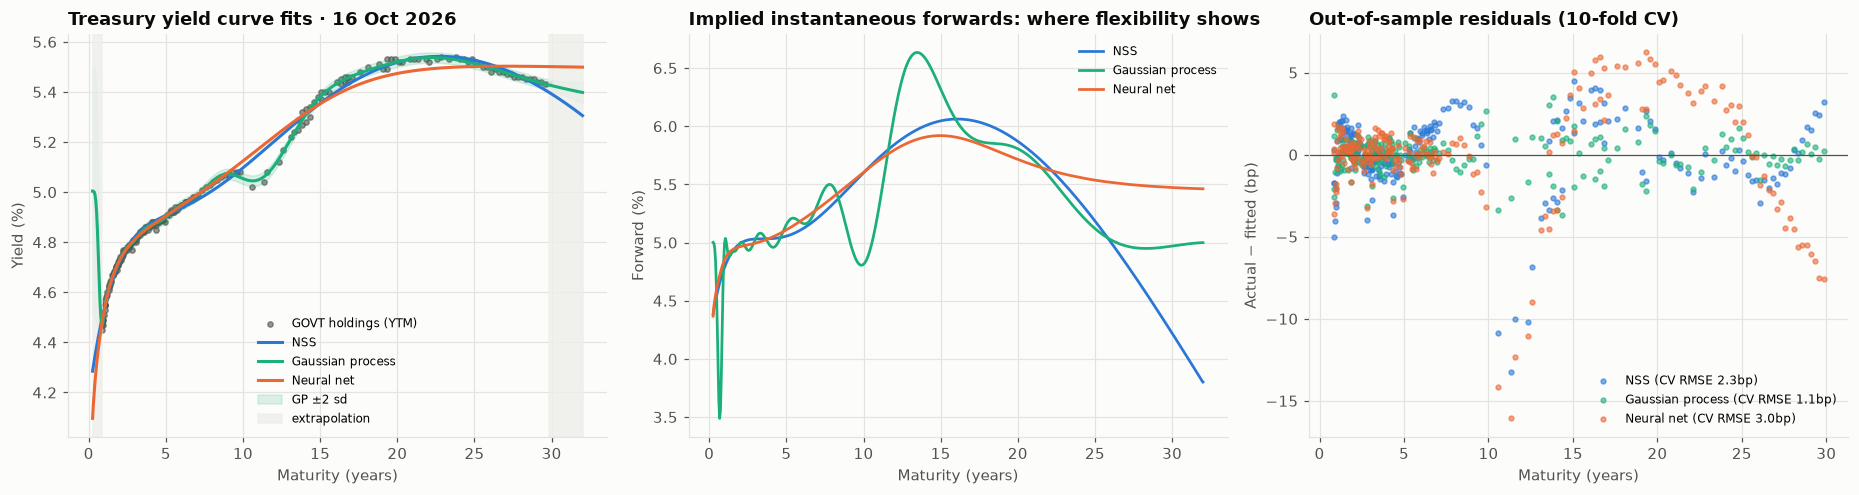

In [7]:
# --- Chart 1: fitted curves, forwards and residuals
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
ax.scatter(X_TAU, Y, s=12, color=INK_2, alpha=0.6, label="GOVT holdings (YTM)")
for name, (f, _) in fits.items():
    ax.plot(TAU_GRID, f(TAU_GRID), color=MODEL_COLORS[name], lw=2, label=name)
gp_mu, gp_sd = fits["Gaussian process"][0].gp.predict(
    np.log(TAU_GRID)[:, None], return_std=True
)
ax.fill_between(
    TAU_GRID,
    gp_mu - 2 * gp_sd,
    gp_mu + 2 * gp_sd,
    color=MODEL_COLORS["Gaussian process"],
    alpha=0.15,
    label="GP ±2 sd",
)
ax.axvspan(
    X_TAU.max(),
    TAU_GRID.max(),
    color="#eeeeea",
    alpha=0.8,
    label="extrapolation",
)
ax.axvspan(TAU_GRID.min(), X_TAU.min(), color="#eeeeea", alpha=0.8)
ax.set_title(f"Treasury yield curve fits · {as_of:%d %b %Y}")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Yield (%)")
ax.legend(fontsize=8)
ax = axes[1]
for name, (f, _) in fits.items():
    c = f(TAU_GRID)
    ax.plot(
        TAU_GRID,
        c + TAU_GRID * np.gradient(c, TAU_GRID),
        color=MODEL_COLORS[name],
        lw=1.8,
        label=name,
    )
ax.set_title("Implied instantaneous forwards: where flexibility shows")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Forward (%)")
ax.legend(fontsize=8)
ax = axes[2]
for name in FITTERS:
    ax.scatter(
        X_TAU,
        cv_resid[name],
        s=10,
        color=MODEL_COLORS[name],
        alpha=0.6,
        label=f"{name} (CV RMSE {scorecard.loc[name, 'CV RMSE (bp)']:.1f}bp)",
    )
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Out-of-sample residuals (10-fold CV)")
ax.set_xlabel("Maturity (years)")
ax.set_ylabel("Actual − fitted (bp)")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_fits_forwards_residuals")
plt.show()

## 6. Rich / cheap: do the models agree on relative value?

A bond above the curve is **cheap** (high yield for its maturity) and one below is **rich**. Relative-value desks trade these residuals, and a risk function checks that a signal is not an artefact of one model. Agreement between models is measured by the rank correlation of in-sample residuals.

In [8]:
resid = pd.DataFrame(
    {name: (Y - f(X_TAU)) * 100 for name, (f, _) in fits.items()}
)
resid.insert(0, "maturity_y", X_TAU)
resid.insert(
    0,
    "bond",
    ust["name"].str.title()
    + " "
    + ust["coupon_pct"].map("{:.3f}%".format)
    + " "
    + ust["maturity"].dt.strftime("%b-%Y"),
)
agreement = resid[list(FITTERS)].corr(method="spearman")
resid["average"] = resid[list(FITTERS)].mean(axis=1)
rich_cheap = pd.concat([
    resid.nlargest(5, "average").assign(signal="cheap"),
    resid.nsmallest(5, "average").assign(signal="rich"),
])
display(agreement.round(2))
rich_cheap.round(1)

,NSS,Gaussian process,Neural net
NSS,1.00,0.41,0.48
Gaussian process,0.41,1.00,0.42
Neural net,0.48,0.42,1.00


,bond,maturity_y,NSS,Gaussian process,Neural net,average,signal
187,Treasury Bond 2.500% Feb-2046,19.30,2.50,2.00,6.50,3.70,cheap
178,Treasury Bond 2.880% May-2043,16.60,3.90,1.00,5.40,3.40,cheap
172,Treasury Bond 2.000% Nov-2041,15.10,4.20,1.40,4.40,3.40,cheap
184,Treasury Bond 3.000% Nov-2044,18.10,2.70,1.40,5.70,3.30,cheap
177,Treasury Bond 3.130% Feb-2043,16.30,3.80,0.80,5.20,3.30,cheap
155,Treasury Bond 4.380% Feb-2038,11.30,-12.70,-2.00,-14.90,-9.90,rich
154,Treasury Bond 5.000% May-2037,10.60,-10.70,-2.50,-13.20,-8.80,rich
157,Treasury Bond 3.500% Feb-2039,12.30,-10.00,-1.40,-11.70,-7.70,rich
156,Treasury Bond 4.500% May-2038,11.60,-10.00,0.70,-12.10,-7.10,rich
158,Treasury Bond 4.250% May-2039,12.60,-6.30,1.20,-7.90,-4.30,rich


## 7. Stability through time: leave-one-tenor-out on the daily par curve

A curve model is used every day, so it must behave the same way every day. For the first trading day of each month of 2026, the official Treasury par curve (1 month to 30 years) is refitted by all three models with one tenor left out (3 months to 20 years in turn), and the left-out yield is predicted.

This is the "missing bond" problem curve builders face whenever a point is illiquid or stale. The NN is refitted with fewer steps to keep the exercise fast.

In [9]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_par():
    raw = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=dt.date.today().year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par = (
    cached("treasury_par_curves", fetch_par)
    .pivot(index="date", columns="tenor", values="par_yield")
    .sort_index()
)
# tenors present all year
par = par[
    [t for t in par.columns if t not in (1.5 / 12, 4 / 12, 1.5)]
].dropna()
# first trading day of each month
weekly = par.groupby(par.index.to_period("M")).head(1)
LEAVE_OUT = [t for t in par.columns if 0.25 <= t <= 20]
fast = {
    "NSS": fit_nss,
    "Gaussian process": fit_gp,
    "Neural net": lambda t, y: fit_nn(t, y, steps=400),
}
NN_ENSEMBLE_SAVED, NN_ENSEMBLE = NN_ENSEMBLE, 2
t0 = time.perf_counter()
loo = []
for d, row in weekly.iterrows():
    tau, yv = row.index.to_numpy(dtype=float), row.to_numpy(dtype=float)
    for t_out in LEAVE_OUT:
        keep = tau != t_out
        for name, fitter in fast.items():
            f, _ = fitter(tau[keep], yv[keep])
            loo.append({
                "date": d,
                "tenor": t_out,
                "model": name,
                "error_bp": (row[t_out] - f(np.array([t_out]))[0]) * 100,
            })
NN_ENSEMBLE = NN_ENSEMBLE_SAVED
loo = pd.DataFrame(loo)
print(
    f"{len(weekly)} monthly curves × {len(LEAVE_OUT)} left-out tenors × 3"
    f" models in {time.perf_counter() - t0:.0f}s"
)
loo_tbl = loo.assign(abs_err=loo["error_bp"].abs()).pivot_table(
    index="tenor", columns="model", values="abs_err", aggfunc="mean"
)
loo_tbl.index = [
    f"{int(t*12)}M" if t < 1 else f"{t:g}Y" for t in loo_tbl.index
]
loo_tbl.loc["all tenors"] = loo.groupby("model")["error_bp"].apply(
    lambda e: e.abs().mean()
)
loo_tbl.round(1)

…/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-07. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


…/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-07. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


10 monthly curves × 9 left-out tenors × 3 models in 154s


model,Gaussian process,NSS,Neural net
3M,2.10,2.00,1.70
6M,4.50,3.00,3.60
1Y,6.90,6.50,5.80
2Y,4.80,3.40,3.90
3Y,2.80,1.20,1.00
5Y,3.30,2.20,2.10
7Y,4.90,2.60,1.60
10Y,8.20,5.00,8.70
20Y,17.50,16.90,17.40
all tenors,6.10,4.70,5.10


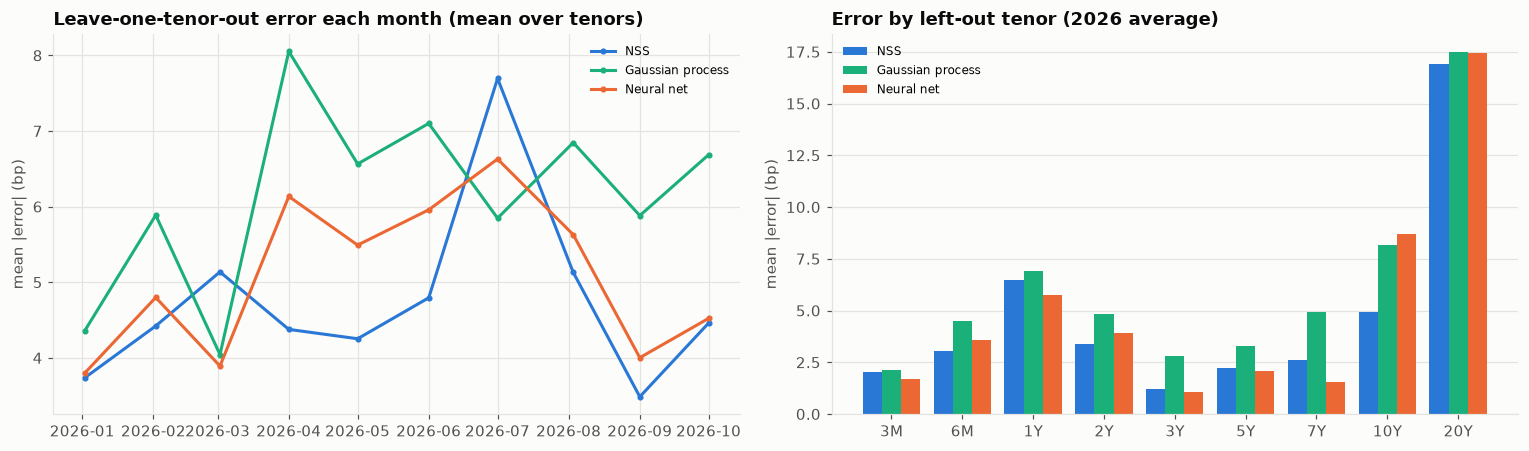

In [10]:
# --- Chart 2: stability through time
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
by_date = (
    loo.assign(abs_err=loo["error_bp"].abs())
    .groupby(["date", "model"])["abs_err"]
    .mean()
    .unstack()
)
for name in FITTERS:
    ax.plot(
        by_date.index,
        by_date[name],
        color=MODEL_COLORS[name],
        marker="o",
        ms=3,
        label=name,
    )
ax.set_title("Leave-one-tenor-out error each month (mean over tenors)")
ax.set_ylabel("mean |error| (bp)")
ax.legend(fontsize=8)
ax = axes[1]
lt = loo_tbl.drop(index="all tenors")
xp = np.arange(len(lt))
for k, name in enumerate(FITTERS):
    ax.bar(
        xp + (k - 1) * 0.27,
        lt[name],
        0.27,
        color=MODEL_COLORS[name],
        label=name,
    )
ax.set_xticks(xp, lt.index)
ax.set_title("Error by left-out tenor (2026 average)")
ax.set_ylabel("mean |error| (bp)")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()
save_fig(fig, "02_stability_leave_one_tenor_out")
plt.show()
scorecard.to_csv(OUT_DIR / "curve_fit_scorecard.csv")
resid.to_csv(OUT_DIR / "bond_residuals_by_model.csv", index=False)
loo.to_csv(OUT_DIR / "leave_one_tenor_out_2026.csv", index=False)

## 8. Reading the results and limitations

Run on GOVT holdings as of 16 Oct 2026 (226 notes and bonds, 0.8–29.8 years):

**The Gaussian process prices best out of sample** (CV RMSE 1.1 bp, against 2.3 bp for NSS and 3.0 bp for the NN), because it follows the real local structure of the Treasury curve: the 10–13-year "old 20-year bonds" pocket and the hump at 20–25 years.

It pays for that in **roughness** (3× NSS) and three turning points. Its forwards oscillate between 3.5% and 6.6%, and outside the data it reverts toward its mean: below the shortest bond (0.8 years) it jumps to 5%. A GP curve must not be used for key-rate durations or extrapolation without constraints.

**NSS is the balanced choice** and the reason central banks use it: 2.3 bp CV error with a single turning point. Its parameters are poorly identified, though: β0 (the yield at infinite maturity) comes out at −4.1% while a second hump (β3 = 27) does the work. Each curve looks fine, but the parameters can jump from day to day, which matters if NSS factors are used as risk drivers.

- **The NN, with its curvature penalty, is the smoothest** (lowest forward range) but **underfits**, and is worst on the 10–30-year sector (5.2 bp). The penalty that removes oscillations also removes real structure. Tuning the penalty is the practical difficulty of ML curves.
- **Relative value is model-dependent.** The rank correlation of residuals between models is only 0.4–0.5. All three agree that the 2037–2039 bonds are rich (−4 to −15 bp) and the 2041–2046 bonds slightly cheap. Below that magnitude, "rich/cheap" is mostly an artefact of the curve model.

**Missing-tenor test on the 2026 par curves:** NSS has the smallest average leave-one-out error (4.7 bp, against 5.1 bp for the NN and 6.1 bp for the GP). With only 12 points, the GP's flexibility becomes a liability. Every model misses the **20-year** point by about 17 bp: the 20-year hump cannot be recovered from the 10- and 30-year points. Removing an illiquid tenor removes information no model can recreate.

**Limitations**

- Yields to maturity are fitted directly, a common simplification. A production curve fits *prices* through a discount function, so coupon effects are priced exactly. The ranking of the models does not change, but the residuals do by a few bp for high-coupon bonds.
- Holdings yields are the fund's marks at its valuation time, with no bid/ask or on-the-run/off-the-run adjustment.
- The NN and GP hyper-parameters (penalty, kernel bounds) were set once and not tuned on the test folds; tuning them would narrow the gap to NSS in-sample but not change the extrapolation behaviour.

## References

### Finance and regulation

- Svensson, L. E. O. (1994). *Estimating and interpreting forward interest rates: Sweden 1992–1994* (NBER Working Paper No. 4871). National Bureau of Economic Research. https://doi.org/10.3386/w4871
- Gürkaynak, R. S., Sack, B., & Wright, J. H. (2007). The U.S. Treasury yield curve: 1961 to the present. *Journal of Monetary Economics, 54*(8), 2291–2304. https://doi.org/10.1016/j.jmoneco.2007.06.029
- Bank for International Settlements. (2005). *Zero-coupon yield curves: Technical documentation* (BIS Papers No. 25). https://www.bis.org/publ/bppdf/bispap25.htm
- Hagan, P. S., & West, G. (2006). Interpolation methods for curve construction. *Applied Mathematical Finance, 13*(2), 89–129. https://doi.org/10.1080/13504860500396032

### Machine learning and deep learning

- Rasmussen, C. E., & Williams, C. K. I. (2006). *Gaussian processes for machine learning*. MIT Press. https://gaussianprocess.org/gpml/
- Filipović, D., Pelger, M., & Ye, Y. (2022). *Stripping the discount curve: A robust machine learning approach*. SSRN. https://doi.org/10.2139/ssrn.4058150
- Lakshminarayanan, B., Pritzel, A., & Blundell, C. (2017). Simple and scalable predictive uncertainty estimation using deep ensembles. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1612.01474
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703